<a href="https://colab.research.google.com/github/matildadaniela/Book-scraping-project/blob/main/Book_Scraping_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Install libraries and load them

In [ ]:
!pip install beautifulsoup4
!pip install requests


In [ ]:
import requests
from bs4 import BeautifulSoup as bs

#1. Scrape all non-fiction and fiction books

In [ ]:
from urllib.parse import urljoin

title_list = []
category_list = []
url_list = []
description_list = []
image_list = []

#fiction book scraping
for i in range (1,5):
  url = f"https://books.toscrape.com/catalogue/category/books/fiction_10/page-{i}.html"
  soup = bs(requests.get(url).content, 'html.parser')
  all_books = soup.find_all('article', class_ = 'product_pod')

  for book in all_books:
    #link
    link = urljoin(url, book.find('h3').find('a')['href'])

    #get to the book page
    book_soup = bs(requests.get(link).content, 'html.parser')

    #title
    title = book.find('h3').find('a')['title']

    #category
    category = book_soup.find('ul', class_='breadcrumb').find_all('a')[2].text.strip()

    #description
    description = book_soup.find('div', id = 'product_description').find_next_sibling('p').text.strip()

    #image
    image = urljoin(link, book_soup.find('div', class_='item active').find('img')['src'])


    title_list.append(title)
    category_list.append(category)
    url_list.append(link)
    description_list.append(description)
    image_list.append(image)

#Nonfiction book scraping
for i in range (1,7):
  url = f"https://books.toscrape.com/catalogue/category/books/nonfiction_13/page-{i}.html"
  soup = bs(requests.get(url).content, 'html.parser')
  all_books = soup.find_all('article', class_ = 'product_pod')

  for book in all_books:
    #link
    link = urljoin(url, book.find('h3').find('a')['href'])

    #get to the book page
    book_soup = bs(requests.get(link).content, 'html.parser')

    #title
    title = book.find('h3').find('a')['title']

    #category
    category = book_soup.find('ul', class_='breadcrumb').find_all('a')[2].text.strip()

    #description
    description = book_soup.find('div', id = 'product_description').find_next_sibling('p').text.strip()

    #image
    image = urljoin(link, book_soup.find('div', class_='item active').find('img')['src'])


    title_list.append(title)
    category_list.append(category)
    url_list.append(link)
    description_list.append(description)
    image_list.append(image)


#2. Data cleaning and analysis

In [ ]:
import pandas as pd

#Storing all the relevant data in df_all DataFrame

df_all = pd.DataFrame({'Title': title_list, 'Category': category_list, 'Description': description_list, 'Image': image_list, 'URL': url_list})

# -> CSV
#df_all.to_csv('books.csv', index = False)



In [ ]:
#Examining dataset
df_all.info()
df_all.head()
df_all.tail()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Title        175 non-null    object
 1   Category     175 non-null    object
 2   Description  175 non-null    object
 3   Image        175 non-null    object
 4   URL          175 non-null    object
dtypes: object(5)
memory usage: 7.0+ KB


,Title,Category,Description,Image,URL
170,H is for Hawk,Nonfiction,When Helen Macdonald's father died suddenly on...,https://books.toscrape.com/media/cache/14/00/1...,https://books.toscrape.com/catalogue/h-is-for-...
171,Travels with Charley: In Search of America,Nonfiction,An intimate journey across and in search of Am...,https://books.toscrape.com/media/cache/3f/c2/3...,https://books.toscrape.com/catalogue/travels-w...
172,The Tumor,Nonfiction,John Grisham says THE TUMOR is the most import...,https://books.toscrape.com/media/cache/8a/14/8...,https://books.toscrape.com/catalogue/the-tumor...
173,The End of the Jesus Era (An Investigation #1),Nonfiction,God exists!? This may seem unprovable. The tru...,https://books.toscrape.com/media/cache/fa/9d/f...,https://books.toscrape.com/catalogue/the-end-o...
174,"Eat, Pray, Love",Nonfiction,"In her early thirties, Elizabeth Gilbert had e...",https://books.toscrape.com/media/cache/5b/82/5...,https://books.toscrape.com/catalogue/eat-pray-...


In [ ]:
#Checking for missing values
df_all.isnull().sum()

,0
Title,0
Category,0
Description,0
Image,0
URL,0


In [ ]:
#Checking for duplicates
df_all.duplicated().sum()

np.int64(0)

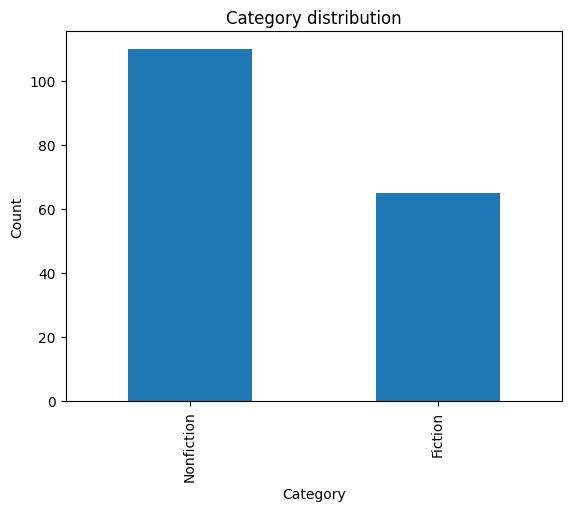

In [ ]:
#Category distribution
import matplotlib.pyplot as plt

df_all['Category'].value_counts().plot(kind='bar')

plt.title('Category distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()


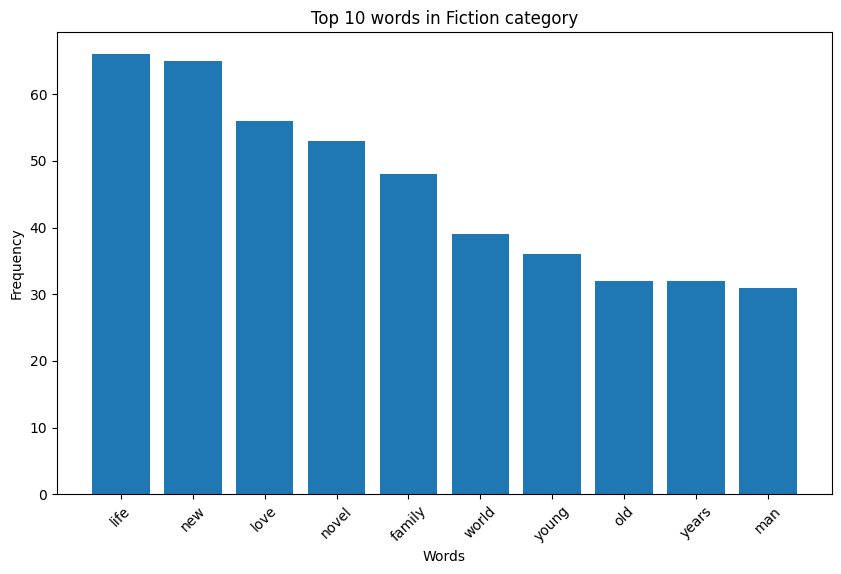

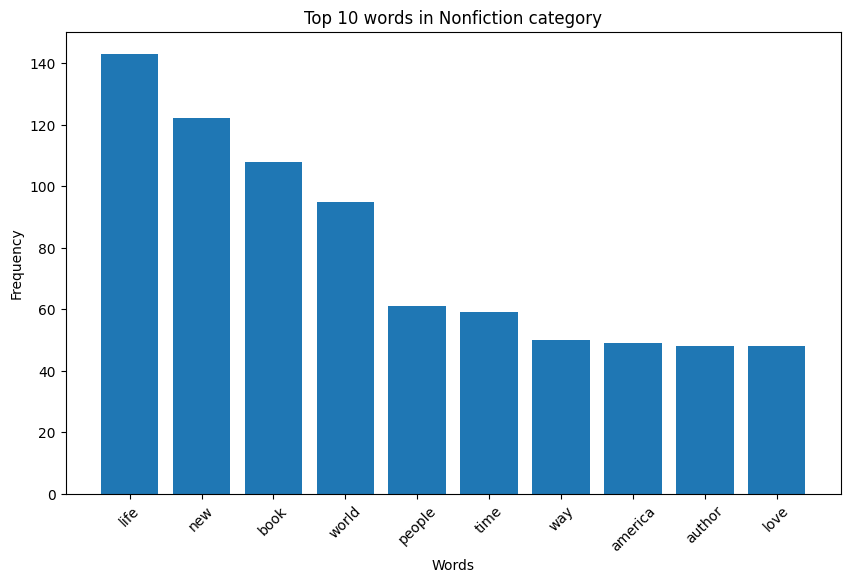

In [ ]:
#Visualisation of most common words in each category
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt

for category in ['Fiction', 'Nonfiction']:

  texts = df_all[df_all['Category'] == category]['Description']

  vectorizer = CountVectorizer(stop_words='english')
  word_counts = vectorizer.fit_transform(texts)

  frequencies = word_counts.sum(axis=0).A1
  words = vectorizer.get_feature_names_out()

  top_words = pd.Series(frequencies, index=words).nlargest(10)

  plt.figure(figsize=(10, 6))
  plt.bar(top_words.index, top_words.values)
  plt.xlabel('Words')
  plt.ylabel('Frequency')
  plt.title(f'Top 10 words in {category} category')
  plt.xticks(rotation=45)
  plt.show()



Category
Fiction       242.723077
Nonfiction    272.936364
Name: Description_length, dtype: float64


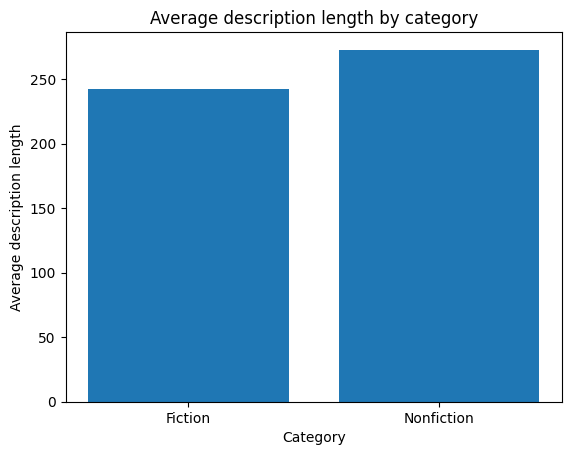

In [ ]:
# Visualisation of average description length
import matplotlib.pyplot as plt

df_all['Description_length'] = df_all['Description'].str.split().str.len()

total_words = df_all.groupby('Category')['Description_length'].sum()
book_count = df_all.groupby('Category')['Description_length'].count()

avg = total_words / book_count
print(avg)

plt.bar(avg.index, avg.values)
plt.xlabel('Category')
plt.ylabel('Average description length')
plt.title('Average description length by category')
plt.show()

#3. Feature engineering

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

#Making a copy of the dataset
df_model = df_all.copy()

#Making a text column combining title and description

df_model['Text'] = (df_model['Title'] + ' ' + df_model['Description'])

#Defining features and target

X = df_model['Text']
y = df_model['Category']

#Splitting the data into training and testing data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#Text -> numerical word count
vectorizer = CountVectorizer(stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(X_train_vec.shape)
print(X_test_vec.shape)

(140, 6182)
(35, 6182)


Experimenting with image feature engineering

In [ ]:
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np

def extract_image_features(image_url):

    response = requests.get(image_url)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content))

    #Convert pixels to numbers
    pixels = np.array(img)

    #Calculate average color
    avg_red = pixels[:, :, 0].mean()
    avg_green = pixels[:, :, 1].mean()
    avg_blue = pixels[:, :, 2].mean()

        # Convert RGB values to grayscale intensity
    grayscale = (
        0.299 * pixels[:, :, 0] +
        0.587 * pixels[:, :, 1] +
        0.114 * pixels[:, :, 2]
    )

    # Brightness and contrast
    brightness = grayscale.mean()
    contrast = grayscale.std()

    return {'avg_red': avg_red, 'avg_green': avg_green, 'avg_blue': avg_blue, 'brightness': brightness, 'contrast': contrast}


single_image_url = df_all['Image'].iloc[0]
features = extract_image_features(single_image_url)
print(features)

{'avg_red': np.float64(237.1269425179264), 'avg_green': np.float64(230.01999529798988), 'avg_blue': np.float64(167.9161631597508), 'avg_intensity': np.float64(211.68770032522235), 'brightness': np.float64(225.0651356529917), 'contrast': np.float64(14.74531376099453)}


In [ ]:
image_features = []

for image_url in df_all['Image']:
  features = extract_image_features(image_url)
  image_features.append(features)

image_features_df = pd.DataFrame(image_features)

df_model = pd.concat([df_model, image_features_df], axis=1)

df_model.head()

,Title,Category,Description,Image,URL,Description_length,Text,avg_red,avg_green,avg_blue,avg_intensity,brightness,contrast,avg_red,avg_green,avg_blue,avg_intensity,brightness,contrast
0,Soumission,Fiction,"Dans une France assez proche de la nôtre, un h...",https://books.toscrape.com/media/cache/ee/cf/e...,https://books.toscrape.com/catalogue/soumissio...,163,Soumission Dans une France assez proche de la ...,237.126943,230.019995,167.916163,211.687700,225.065136,14.745314,237.126943,230.019995,167.916163,211.687700,225.065136,14.745314
1,Private Paris (Private #10),Fiction,Paris is burning--and only Private's Jack Morg...,https://books.toscrape.com/media/cache/05/87/0...,https://books.toscrape.com/catalogue/private-p...,188,Private Paris (Private #10) Paris is burning--...,144.995039,110.991293,113.914102,123.300145,121.491613,93.751851,144.995039,110.991293,113.914102,123.300145,121.491613,93.751851
2,"We Love You, Charlie Freeman",Fiction,"The Freeman family--Charles, Laurel, and their...",https://books.toscrape.com/media/cache/87/a2/8...,https://books.toscrape.com/catalogue/we-love-y...,231,"We Love You, Charlie Freeman The Freeman famil...",42.557500,110.275407,73.527708,75.453539,85.838515,55.465751,42.557500,110.275407,73.527708,75.453539,85.838515,55.465751
3,Thirst,Fiction,"On a searing summer Friday, Eddie Chapman has ...",https://books.toscrape.com/media/cache/8c/54/8...,https://books.toscrape.com/catalogue/thirst_94...,253,"Thirst On a searing summer Friday, Eddie Chapm...",11.618991,9.776594,5.750736,9.048774,9.868523,31.385109,11.618991,9.776594,5.750736,9.048774,9.868523,31.385109
4,The Murder That Never Was (Forensic Instincts #5),Fiction,"Given the opportunity, would you assume someon...",https://books.toscrape.com/media/cache/29/e0/2...,https://books.toscrape.com/catalogue/the-murde...,290,The Murder That Never Was (Forensic Instincts ...,172.325209,47.142576,51.584306,90.350697,85.078541,49.615751,172.325209,47.142576,51.584306,90.350697,85.078541,49.615751


In [ ]:
image_columns = ['avg_red', 'avg_green', 'avg_blue', 'avg_intensity', 'brightness', 'contrast']

df_model.groupby('Category')[image_columns].std()


,avg_red,avg_green,avg_blue,avg_intensity,brightness,contrast
Category,,,,,,
Fiction,59.490281,57.917981,58.908123,53.605852,54.189151,20.591205
Nonfiction,65.134782,64.532743,65.217654,59.689547,60.852115,19.744115


#4. Model training

In [ ]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

#Train the model
model.fit(X_train_vec, y_train)

MultinomialNB()

#5. Model evaluation

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

#Predicting categories for test data
y_pred = model.predict(X_test_vec)

#Calculating evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print('Accuracy:', accuracy)
print('Precision:', precision)
print('Recall:', recall)
print('F1 score:', f1)

print()
print('Classification report:')
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix:')
print(cm)

NameError: name 'model' is not defined

In [ ]:
#Show incorrect predictions

y_pred_test = model.predict(X_test_vec)

results = pd.DataFrame({'Text': X_test.values, 'Actual': y_test.values, 'Predicted': y_pred_test})

incorrect = results[results['Actual'] != results['Predicted']]

print("Incorrect predictions:", len(incorrect))

incorrect

Incorrect predictions: 6


,Text,Actual,Predicted
1,The Firm When Mitch McDeere signed on with Ben...,Fiction,Nonfiction
12,I Am Pilgrim (Pilgrim #1) A breakneck race aga...,Fiction,Nonfiction
13,"Lila (Gilead #3) Marilynne Robinson, one of th...",Fiction,Nonfiction
24,Balloon Animals BALLOON ANIMALS is a pilgrimag...,Fiction,Nonfiction
29,A Walk in the Woods: Rediscovering America on ...,Nonfiction,Fiction
33,Call the Nurse: True Stories of a Country Nurs...,Nonfiction,Fiction
